### Assess the performance of Cell2Spatial using stxBrain ST dataset.
- Author: Huamei Li
- Date: 2023-07-03
- Email: li_hua_mei@163.com
- Institute: Nanjing University

In [3]:
options(warn = -1)
suppressMessages(require(Seurat))
suppressMessages(require(ggplot2))
suppressMessages(require(dplyr))
suppressMessages(require(reticulate))
suppressMessages(require(stringr))
suppressMessages(require(ggpubr))
suppressMessages(require(tidydr))
suppressMessages(require(CellTrek))
suppressMessages(require(CARD))
#devtools::load_all('../Cell2Spatial/')

In [4]:
source('modules/globalParams.R')
source('modules/utils.R')
source('modules/vis.R')
source('modules/reformatProjRes.R')

In [5]:
out.figs.dir <- '../2.results/stxBrain/figs'
out.data.dir <- '../2.results/stxBrain/data'

In [6]:
dir.create(out.figs.dir, showWarnings = FALSE, recursive = TRUE)
dir.create(out.data.dir, showWarnings = FALSE, recursive = TRUE)

In [7]:
f.ctypes <- c("Astro", "L2/3 IT", "L4", "L5 PT", "L5 IT", "L6 CT", "L6 IT", "L6b", "Oligo")

In [8]:
set.seed(1983765) 
markers <- readRDS('../0.data/sctBrain.markers.RDS')# Set random seed
cell.colors <- randomcoloR::distinctColorPalette(length(markers))  %>% `names<-`(names(markers))

In [9]:
MTH_COLOR <- c(
    'Reference'    = 'grey',
    'Cell2Spatial' = '#F7B263',
    'CytoSPACE' = '#D6AA8E',
    'CellTrek' = '#99C0CC',
    'Tangram' = 'lightgreen',
    'Seurat' = '#CC00FF'
)

### Loading stxBrain ST and SC datasets 

In [10]:
brain.st <- readRDS('../0.data/stxBrain/brain.st.rds')

In [11]:
brain.sc <- readRDS('../0.data/stxBrain/allen_cortex.rds')

In [10]:
#xx <- GetAssayData(brain.st, slot = 'count')
#rowSums(xx)

In [11]:
sum(GetAssayData(brain.st, slot = 'count')>0)
sum(GetAssayData(brain.st, slot = 'count')==0)

[1] 15942983

[1] 31689945

In [12]:
31689945 / (15942983 + 31689945)

[1] 0.6652949

In [13]:
max(colSums(GetAssayData(brain.st, slot = 'count')))
median(GetAssayData(brain.st, slot = 'count'))

[1] 25580

[1] 0

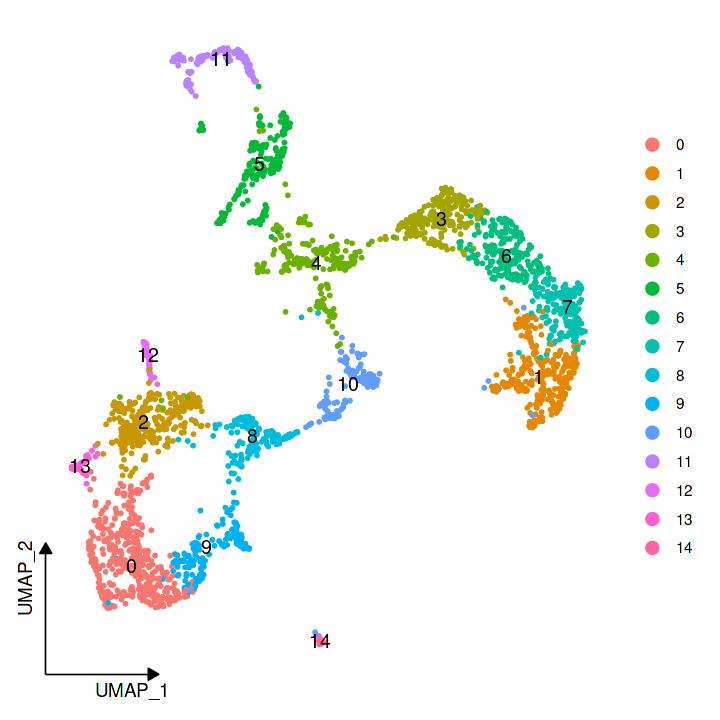

In [14]:
options(repr.plot.width = 6, repr.plot.height = 6)
DimPlot(brain.st, reduction = "umap", label = TRUE) + theme_dr(xlength = 0.2, ylength = 0.2, arrow = grid::arrow(length = unit(0.1, "inches"), ends = 'last', type = "closed")) + theme(panel.grid = element_blank())
ggsave(file.path(out.figs.dir, 'brain.ST.cluster.UMAP.dimplot.pdf'), width = 6, height = 6)

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


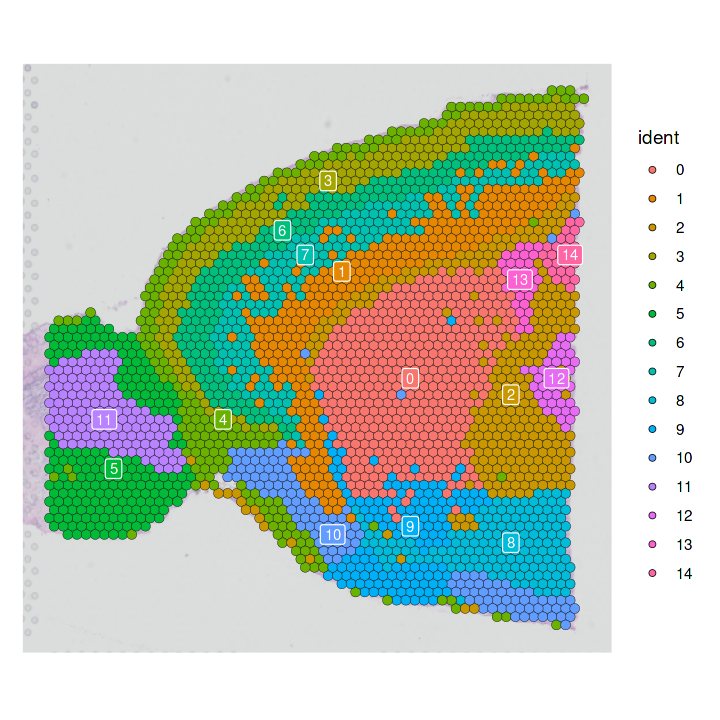

In [15]:
options(repr.plot.width = 6, repr.plot.height = 6)
SpatialDimPlot(brain.st, label = TRUE, label.size = 3, image.alpha = 0.5)
ggsave(file.path(out.figs.dir, 'brain.ST.cluster.UMAP.spatial.pdf'), width = 6, height = 6)

In [16]:
dim(brain.st)

[1] 17668  2696

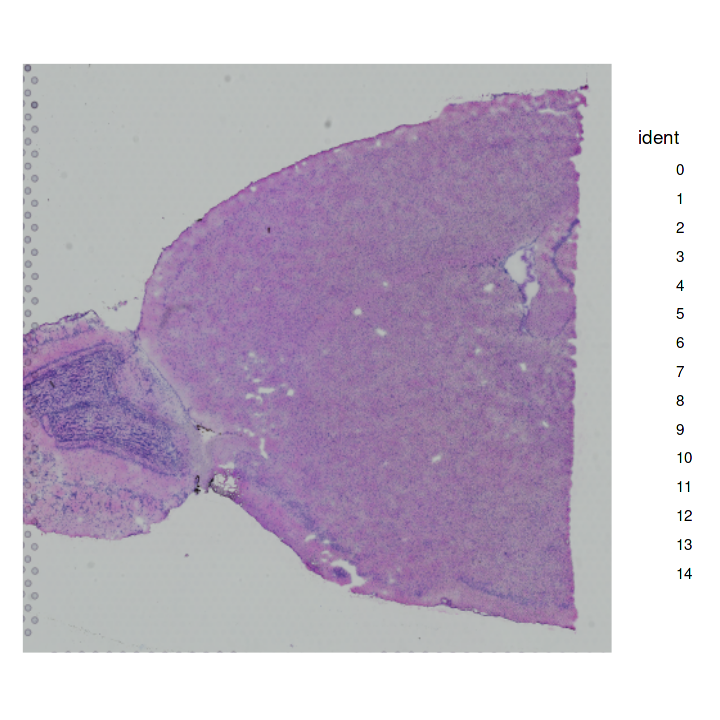

In [17]:
options(repr.plot.width = 6, repr.plot.height = 6)
SpatialDimPlot(brain.st, label = FALSE, label.size = 3,, alpha = 0)
ggsave(file.path(out.figs.dir, 'brain.ST.Image.spatial.pdf'), width = 6, height = 6)

In [18]:
Idents(brain.sc) <- brain.sc$subclass
levels(brain.sc) <- names(markers)

In [19]:
brain.sc <- SCTransform(brain.sc, ncells = 3000, verbose = FALSE) %>%
    RunPCA(verbose = FALSE) %>%
    RunUMAP(dims = 1 : 30, verbose = FALSE)

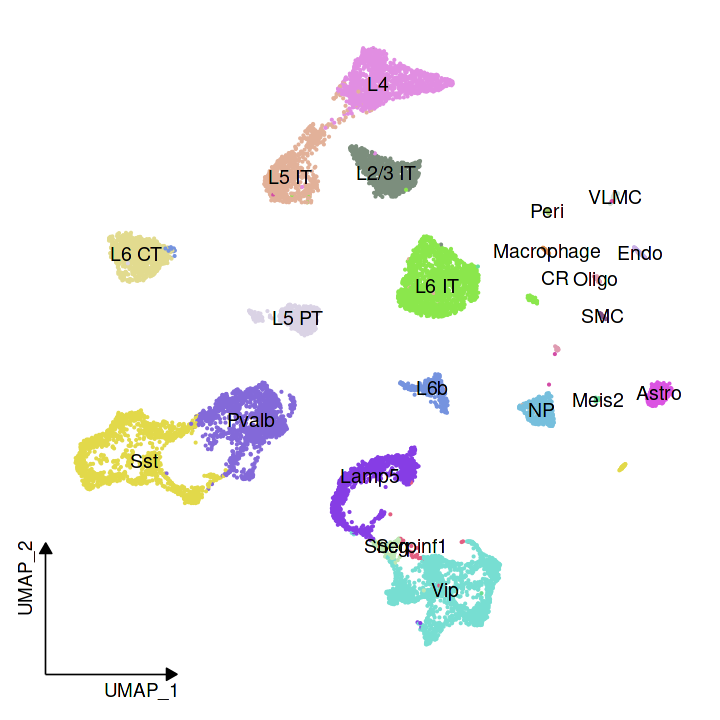

In [20]:
options(repr.plot.width = 6, repr.plot.height = 6)
DimPlot(brain.sc, label = TRUE, cols = cell.colors) + theme_dr(xlength = 0.2, ylength = 0.2, arrow = grid::arrow(length = unit(0.1, "inches"), ends = 'last', type = "closed")) + theme(panel.grid = element_blank()) + NoLegend()
ggsave(file.path(out.figs.dir, 'brain.SC.cluster.UMAP.dimplot.pdf'), width = 6, height = 6)

In [21]:
dim(brain.sc)

[1] 34608 14249

In [22]:
levels(brain.sc) %>% length

[1] 23

In [16]:
#anchors <- FindTransferAnchors(reference = brain.sc, query = brain.st, normalization.method = "SCT")
#predictions.assay <- TransferData(anchorset = anchors, refdata = brain.sc$subclass, prediction.assay = TRUE,
#    weight.reduction = cortex[["pca"]], dims = 1:30)
#brain.st[["predictions"]] <- predictions.assay

In [16]:
#saveRDS(brain.sc, file = file.path(out.data.dir, 'brain.sc.RDS'))
#saveRDS(brain.st, file = file.path(out.data.dir, 'brain.st.RDS'))

### Showing the projection performance for Cell2Spatial

In [1]:
cell2spatial <- readRDS('../2.results/stxBrain/data/stxBrain.cell2spatial.RDS')$obj

In [27]:
sp.lst <- split(cell2spatial$Cell, cell2spatial$SpotName)
sc.mat <- GetAssayData(brain.sc, slot = 'count')
mat <- parallel::mclapply(sp.lst, function(xx) {
    xx <- gsub('\\..*', '', xx)
    if (length(xx) > 1) rowSums(sc.mat[, xx])
    else sc.mat[, xx]
}, mc.cores = 10) %>% do.call(cbind, .) %>% as.data.frame
mat <- DropletUtils::downsampleMatrix(mat, prop = 25000 / colSums(mat))
obj.cell2spatial <- CreateSeuratObject(count = mat, assay = 'Spatial') %>% SCTransform(verbose = FALSE, assay = 'Spatial')

In [28]:
obj.cell2spatial@images <- brain.st@images

In [36]:
obj.cell2spatial <- subset(obj.cell2spatial, anterior1_imagerow > 400 | anterior1_imagecol < 150, invert = TRUE)
obj.cell2spatial <- subset(obj.cell2spatial, anterior1_imagerow > 275 & anterior1_imagecol > 370, invert = TRUE)
obj.cell2spatial <- subset(obj.cell2spatial, anterior1_imagerow > 250 & anterior1_imagecol > 440, invert = TRUE)

In [38]:
brain.st.sub <- subset(brain.st, anterior1_imagerow > 400 | anterior1_imagecol < 150, invert = TRUE)
brain.st.sub <- subset(brain.st.sub, anterior1_imagerow > 275 & anterior1_imagecol > 370, invert = TRUE)
brain.st.sub <- subset(brain.st.sub, anterior1_imagerow > 250 & anterior1_imagecol > 440, invert = TRUE)

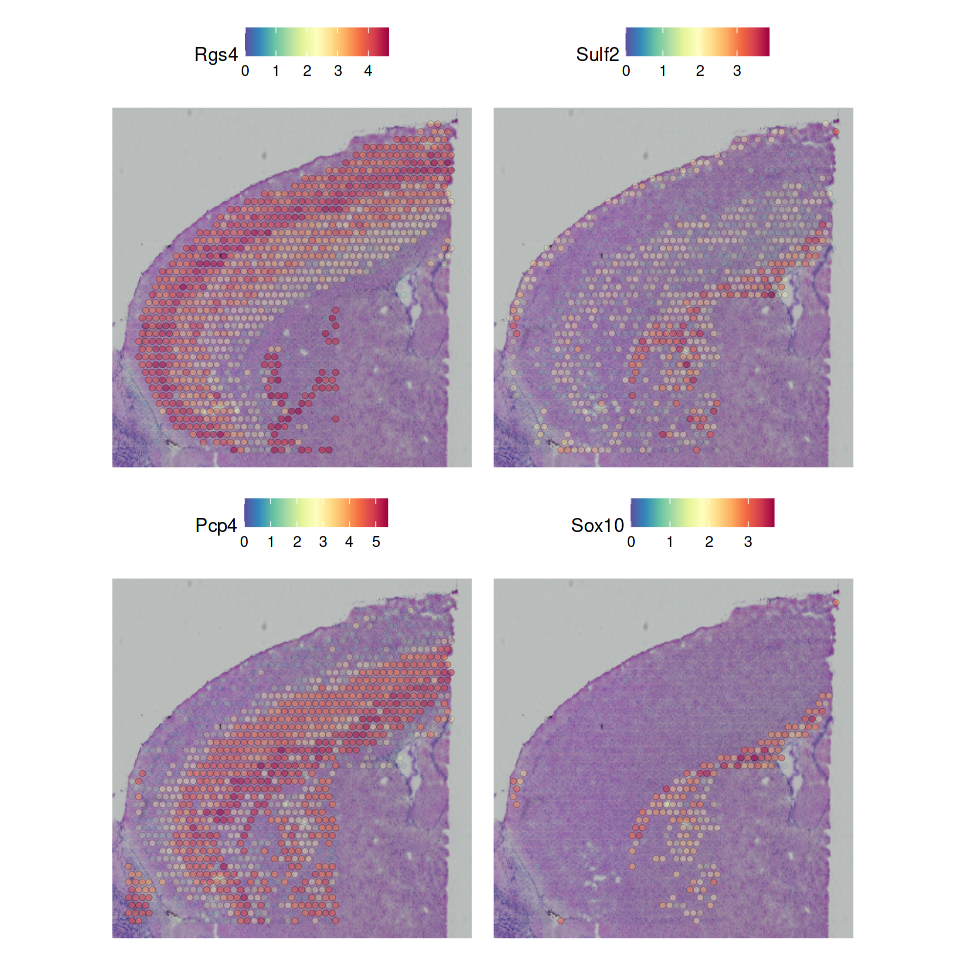

In [62]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialFeaturePlot(obj.cell2spatial, features = c('Rgs4', 'Sulf2', 'Pcp4', 'Sox10'), alpha = c(0.1, 0.6)) 
ggsave(file.path(out.figs.dir, 'gene.expr.comp.pdf'), width = 8, height = 8)

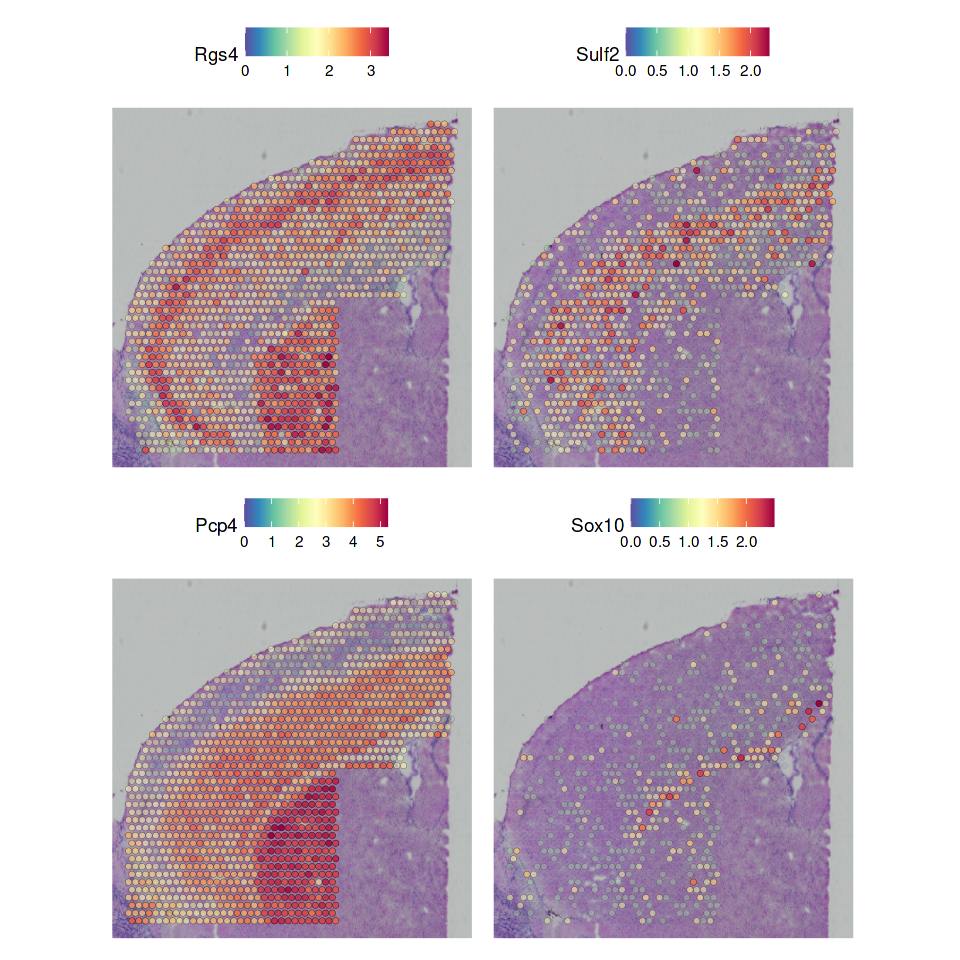

In [63]:
SpatialFeaturePlot(brain.st.sub, features = c('Rgs4', 'Sulf2', 'Pcp4', 'Sox10'), alpha = c(0.1, 1.0))
ggsave(file.path(out.figs.dir, 'gene.expr.comp.visium.pdf'), width = 8, height = 5)

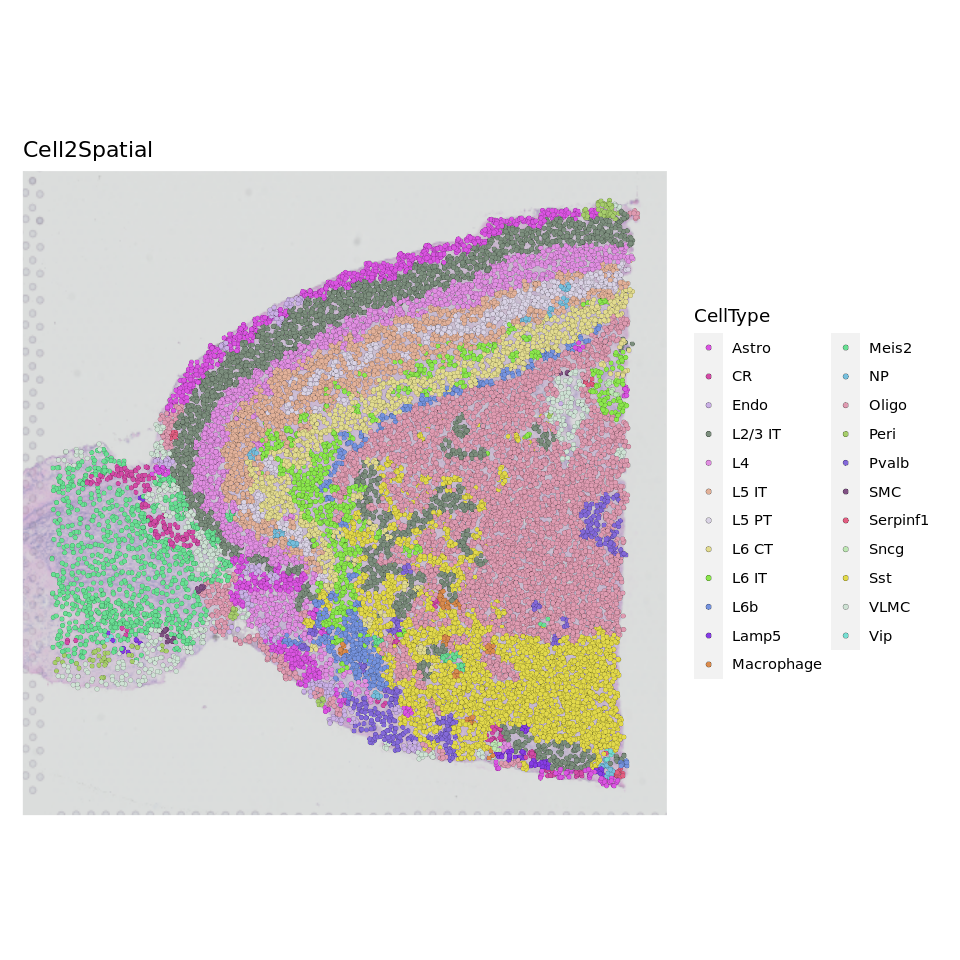

In [17]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(cell2spatial, group.by = 'CellType', pt.size = 0.8, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('Cell2Spatial')
ggsave(file.path(out.figs.dir, 'cell2spatial.entire.UMAP.pdf'), width = 8, height = 6)

In [61]:
cortex <- subset(cell2spatial, anterior1_imagerow > 400 | anterior1_imagecol < 150, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 275 & anterior1_imagecol > 370, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 250 & anterior1_imagecol > 440, invert = TRUE)

In [78]:
f.ctypes <- c('Astro', 'L2/3 IT', 'L4', 'L5 IT', 'L6 CT')
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cortex, CellType == ct) %>% Cells
    obj.sub <- cortex[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 0.5, group.by = 'CellType', cols = cell.colors[ct], pt.size.factor = 1, crop = TRUE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

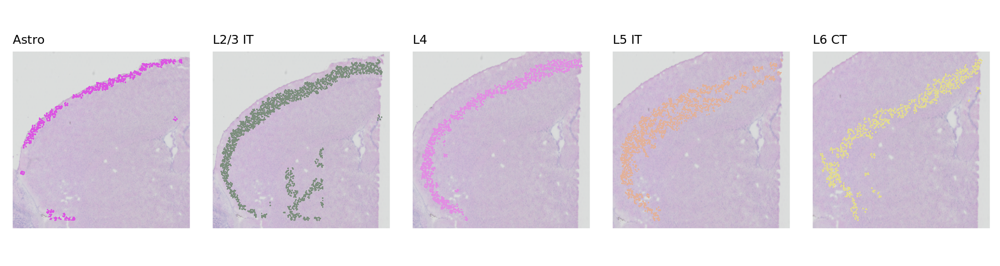

In [79]:
options(repr.plot.width = 15, repr.plot.height = 4)
ggarrange(plotlist = gps, nrow = 1, ncol = 5)
ggsave(file.path(out.figs.dir, 'cell2spatial.split.example.UMAP.pdf'), width = 12, height = 4)
ggsave(file.path(out.figs.dir, 'cell2spatial.split.example.UMAP.eps'), width = 12, height = 4)

In [122]:
f.ctypes <- intersect(names(markers), cell2spatial$CellType %>% unique)
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cell2spatial, CellType == ct) %>% Cells
    obj.sub <- cell2spatial[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 0.5, group.by = 'CellType', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

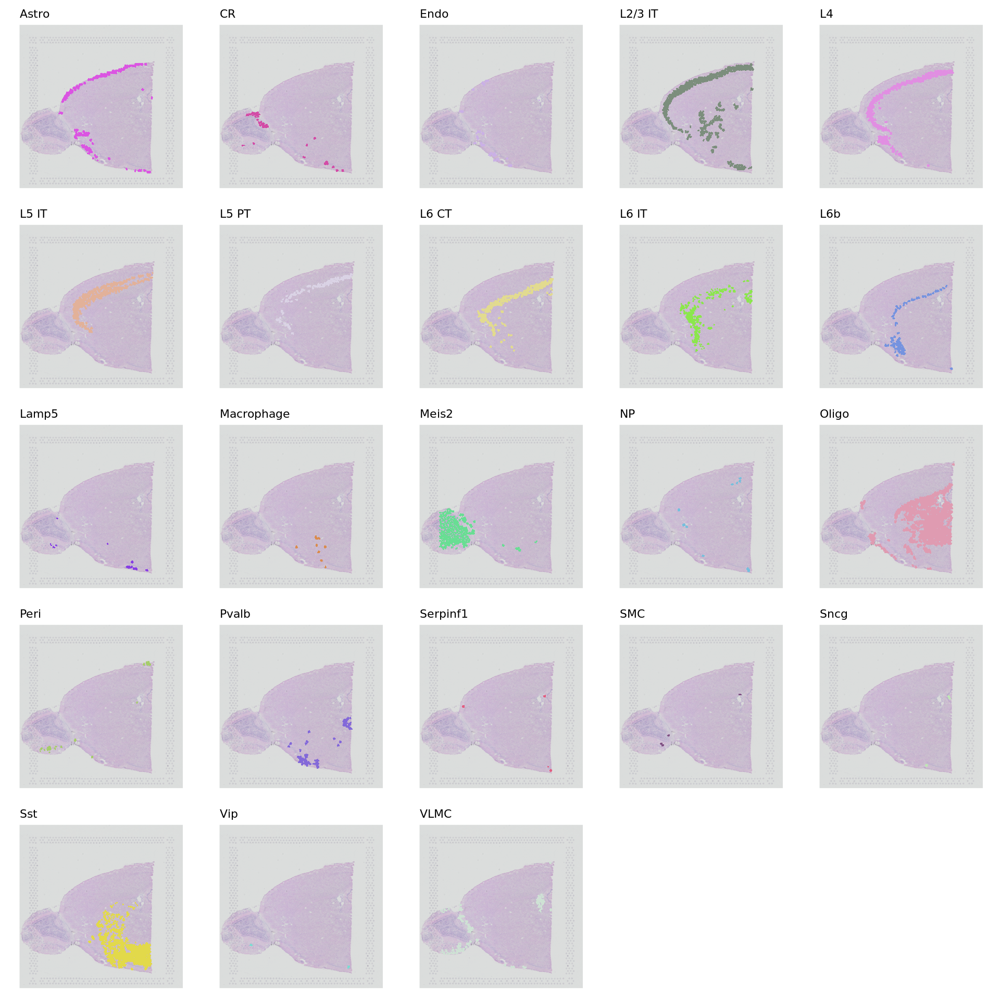

In [123]:
options(repr.plot.width = 16, repr.plot.height = 16)
ggarrange(plotlist = gps, nrow = 5, ncol = 5)
ggsave(file.path(out.figs.dir, 'cell2spatial.split.UMAP.pdf'), width = 16, height = 16)
ggsave(file.path(out.figs.dir, 'cell2spatial.split.UMAP.eps'), width = 16, height = 16)

### Showing the projection performance for CytoSpace

In [66]:
cytospace <- forCytoSpace('../2.results/stxBrain/data/cytospace', brain.sc, brain.st)

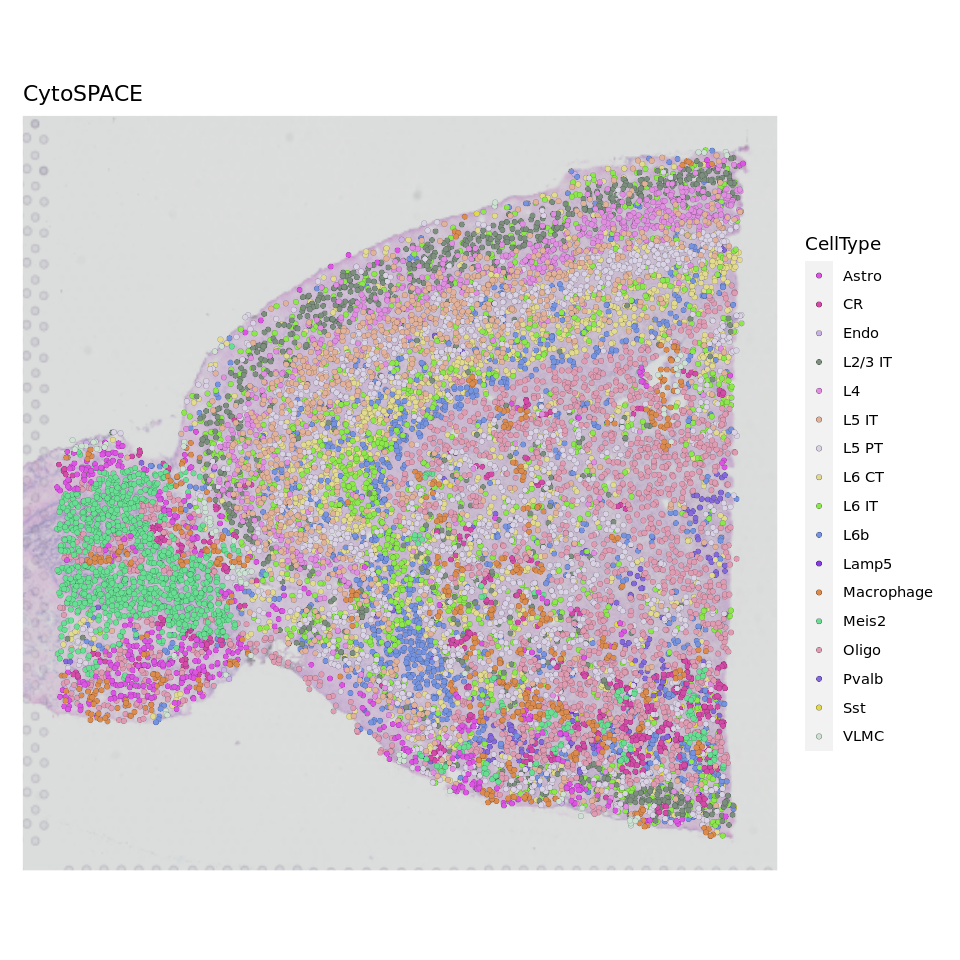

In [18]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(cytospace, group.by = 'CellType', pt.size = 0.8, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('CytoSPACE')
ggsave(file.path(out.figs.dir, 'cytospace.entire.UMAP.pdf'), width = 8, height = 6)

In [19]:
f.ctypes <- intersect(names(markers), cytospace$CellType %>% unique)
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cytospace, CellType == ct) %>% Cells
    obj.sub <- cytospace[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 0.5, group.by = 'CellType', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

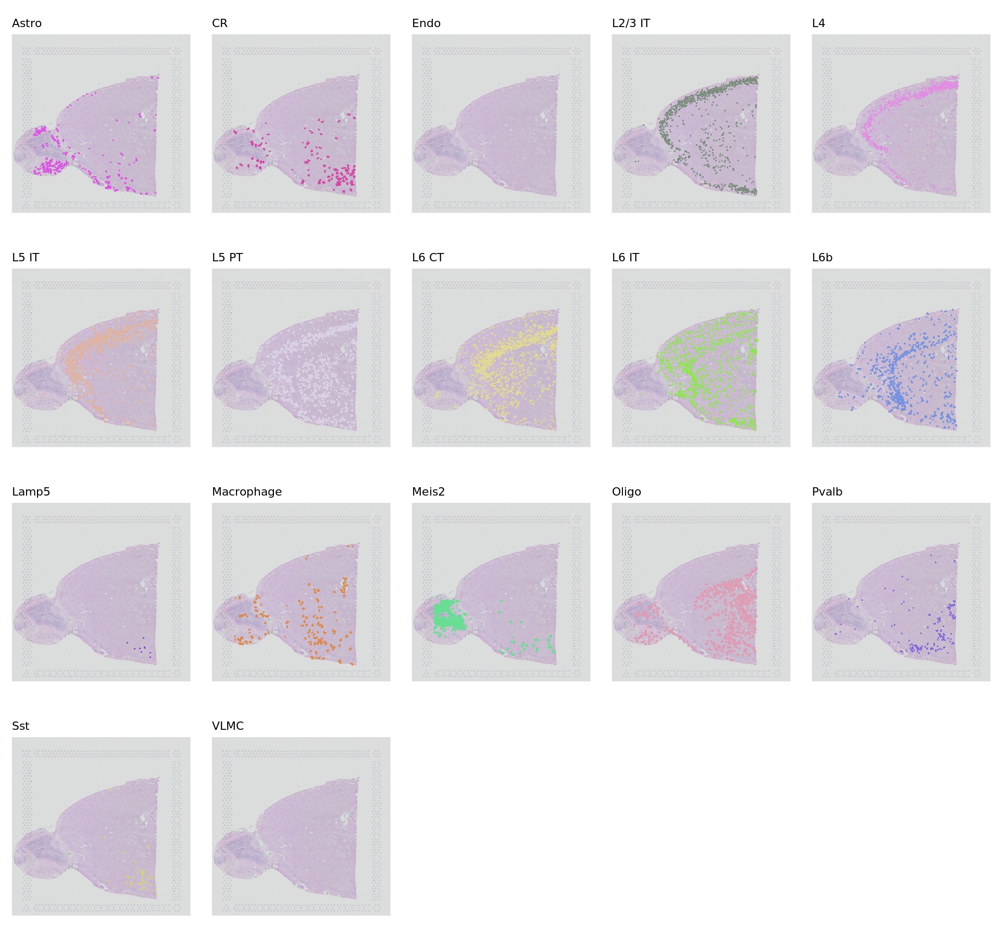

In [20]:
options(repr.plot.width = 16, repr.plot.height = 15)
ggarrange(plotlist = gps, nrow = 4, ncol = 5)
ggsave(file.path(out.figs.dir, 'cytospace.split.UMAP.pdf'), width = 16, height = 15)
ggsave(file.path(out.figs.dir, 'cytospace.split.UMAP.eps'), width = 16, height = 15)

### Showing the projection performance for tangram

In [67]:
tangram <- forTangram('../2.results/stxBrain/data/stxBrain_tangram.xls', brain.sc, brain.st)

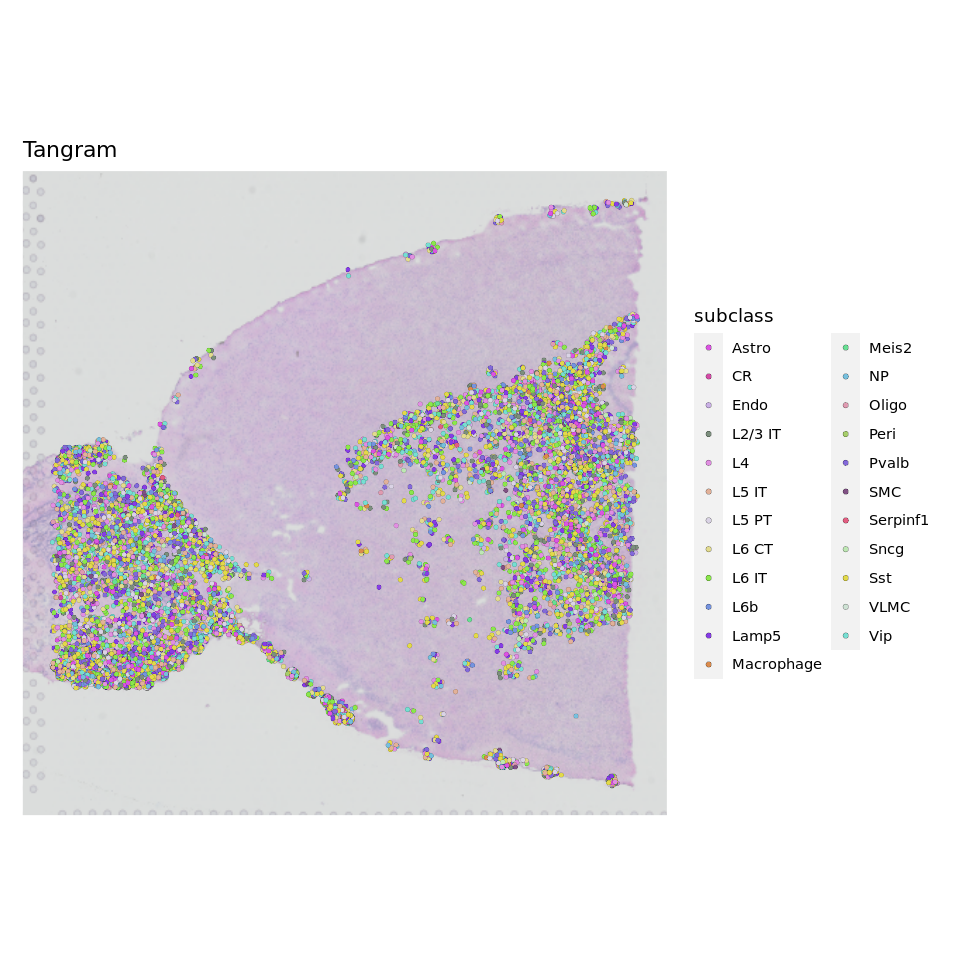

In [26]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(tangram, group.by = 'subclass', pt.size = 0.8, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('Tangram')
ggsave(file.path(out.figs.dir, 'tangram.entire.UMAP.pdf'), width = 8, height = 6)

In [27]:
f.ctypes <- intersect(names(markers), tangram$subclass %>% unique)
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(tangram, subclass == ct) %>% Cells
    obj.sub <- tangram[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 0.5, group.by = 'subclass', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

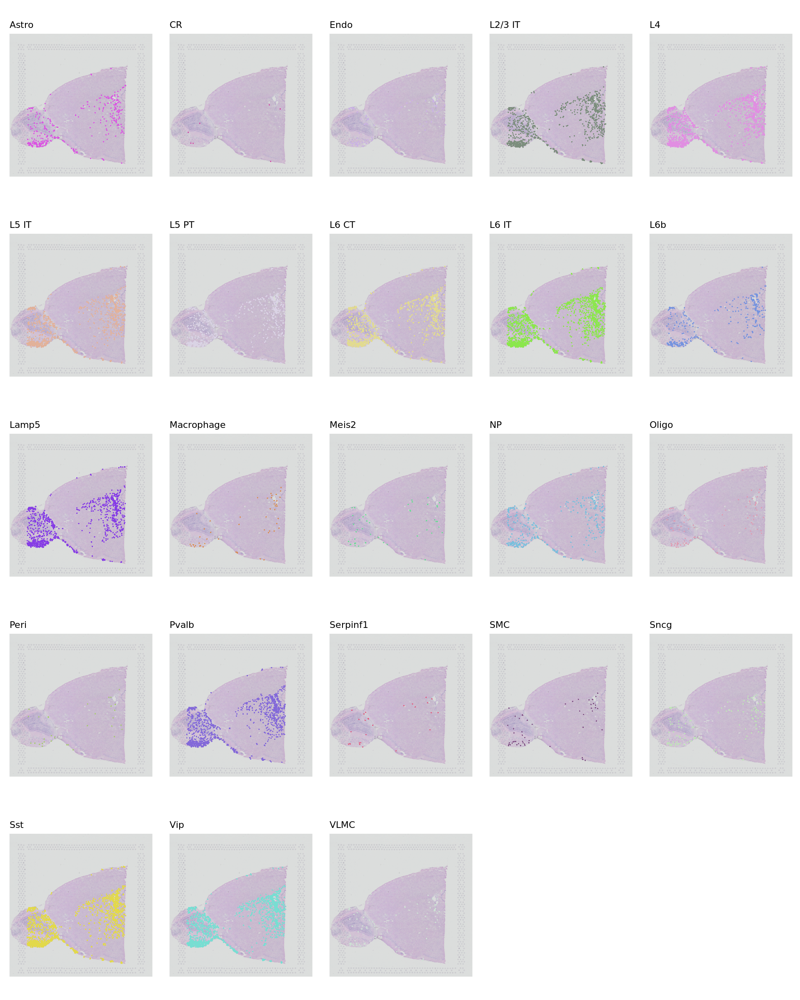

In [28]:
options(repr.plot.width = 16, repr.plot.height = 20)
ggarrange(plotlist = gps, nrow = 5, ncol = 5)
ggsave(file.path(out.figs.dir, 'tangram.split.UMAP.pdf'), width = 16, height = 20)
ggsave(file.path(out.figs.dir, 'tangram.split.UMAP.eps'), width = 16, height = 20)

### Showing the projection performance for Celltrek

In [68]:
cell.trek <- readRDS('../2.results/stxBrain/data/stxBrain.celltrek.RDS') %>% { forCellTrek(list(xx = .), brain.sc, brain.st) }

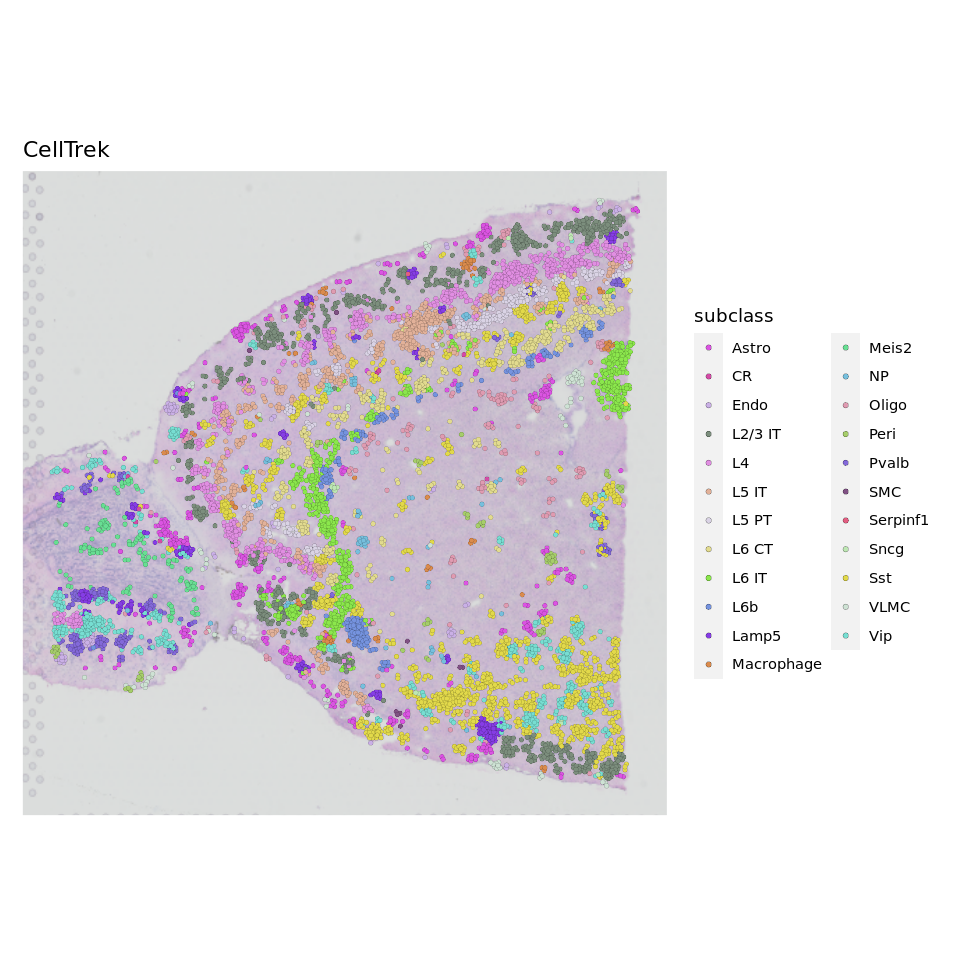

In [30]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(cell.trek, group.by = 'subclass', pt.size = 0.8, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('CellTrek')
ggsave(file.path(out.figs.dir, 'celltrek.entire.UMAP.pdf'), width = 8, height = 6)

In [31]:
f.ctypes <- intersect(names(markers), cell.trek$subclass %>% unique)
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cell.trek, subclass == ct) %>% Cells
    obj.sub <- cell.trek[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 0.5, group.by = 'subclass', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

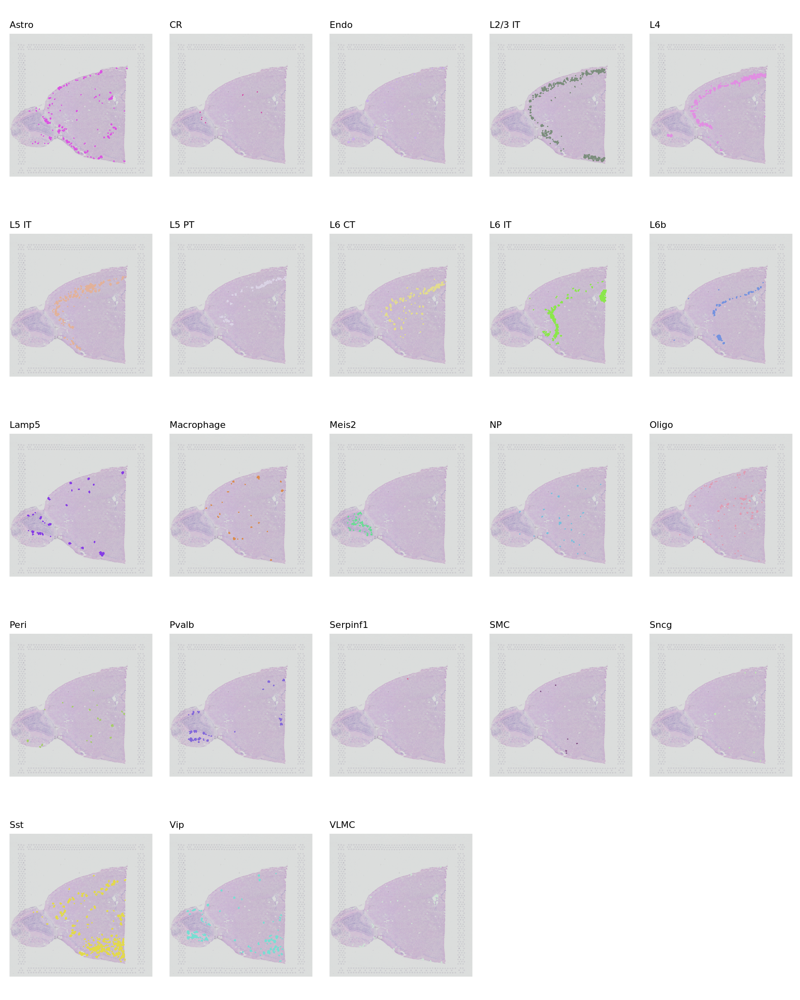

In [32]:
options(repr.plot.width = 16, repr.plot.height = 20)
ggarrange(plotlist = gps, nrow = 5, ncol = 5)
ggsave(file.path(out.figs.dir, 'celltrek.split.UMAP.pdf'), width = 16, height = 20)
ggsave(file.path(out.figs.dir, 'celltrek.split.UMAP.eps'), width = 16, height = 20)

### Showing the projection performance for Seurat

In [62]:
seurat.res <- readRDS('../2.results/stxBrain/data/stxBrain.seurat.update.RDS') 

In [63]:
seurat.res <- forSeuratNew(list(xx = seurat.res), brain.st)

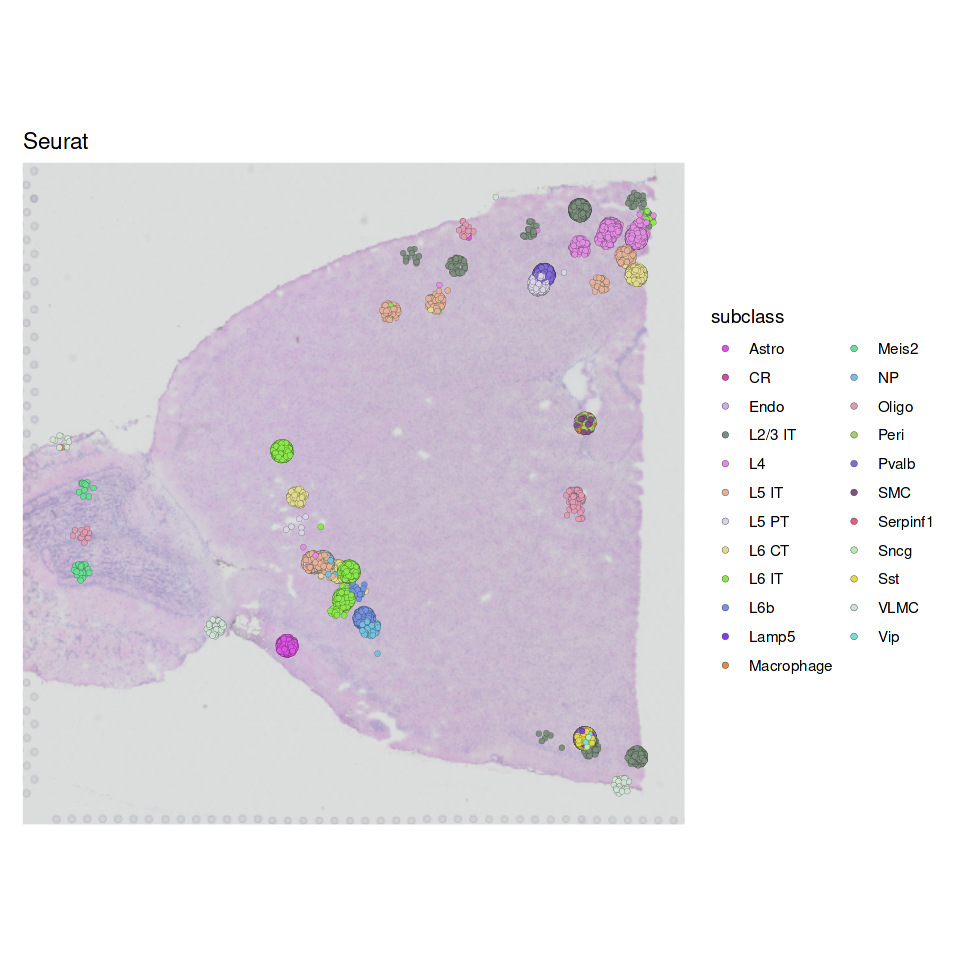

In [64]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(seurat.res, group.by = 'subclass', pt.size = 0.8, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('Seurat')
ggsave(file.path(out.figs.dir, 'seurat.entire.UMAP.update.pdf'), width = 8, height = 6)

In [46]:
seurat.res <- readRDS('../2.results/stxBrain/data/stxBrain.seurat.RDS') 

In [49]:
#seurat.res <- forSeuratNew(list(xx = seurat.res), brain.st)

In [50]:
seurat.res@meta.data %>% head

,orig.ident,nCount_Spatial,nFeature_Spatial,slice,region,nCount_SCT,nFeature_SCT,SCT_snn_res.0.8,seurat_clusters,predicted.id,⋯,prediction.score.NP,prediction.score.L4,prediction.score.L5.IT,prediction.score.Oligo,prediction.score.Meis2,prediction.score.Astro,prediction.score.Macrophage,prediction.score.VLMC,prediction.score.SMC,prediction.score.max
,<fct>,<dbl>,<int>,<dbl>,<chr>,<dbl>,<int>,<fct>,<fct>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAACAAGTATCTCCCA-1,anterior1,11317,4097,1,anterior,19662,4497,2,2,Pvalb,⋯,0,0.0000000,0,0.007239405,0.44147270,0.0000000,0,0.00000000,0,0.5453891
AAACACCAATAACTGC-1,anterior1,32678,7553,1,anterior,20982,7016,5,5,Astro,⋯,0,0.0000000,0,0.257614361,0.01780797,0.4838322,0,0.09003402,0,0.4838322
AAACAGAGCGACTCCT-1,anterior1,23711,6074,1,anterior,21307,6073,3,3,L2/3 IT,⋯,0,0.2150481,0,0.000000000,0.00000000,0.0000000,0,0.00000000,0,0.7677542
AAACAGCTTTCAGAAG-1,anterior1,35869,7640,1,anterior,20832,6838,11,11,Meis2,⋯,0,0.0000000,0,0.000000000,0.99315310,0.0000000,0,0.00000000,0,0.9931531
AAACAGGGTCTATATT-1,anterior1,30710,7475,1,anterior,21056,7154,11,11,Meis2,⋯,0,0.0000000,0,0.000000000,0.92479790,0.0000000,0,0.00000000,0,0.9247979
AAACATGGTGAGAGGA-1,anterior1,18057,6050,1,anterior,19390,6050,5,5,Oligo,⋯,0,0.0000000,0,0.451907280,0.00000000,0.2608266,0,0.27024351,0,0.4519073


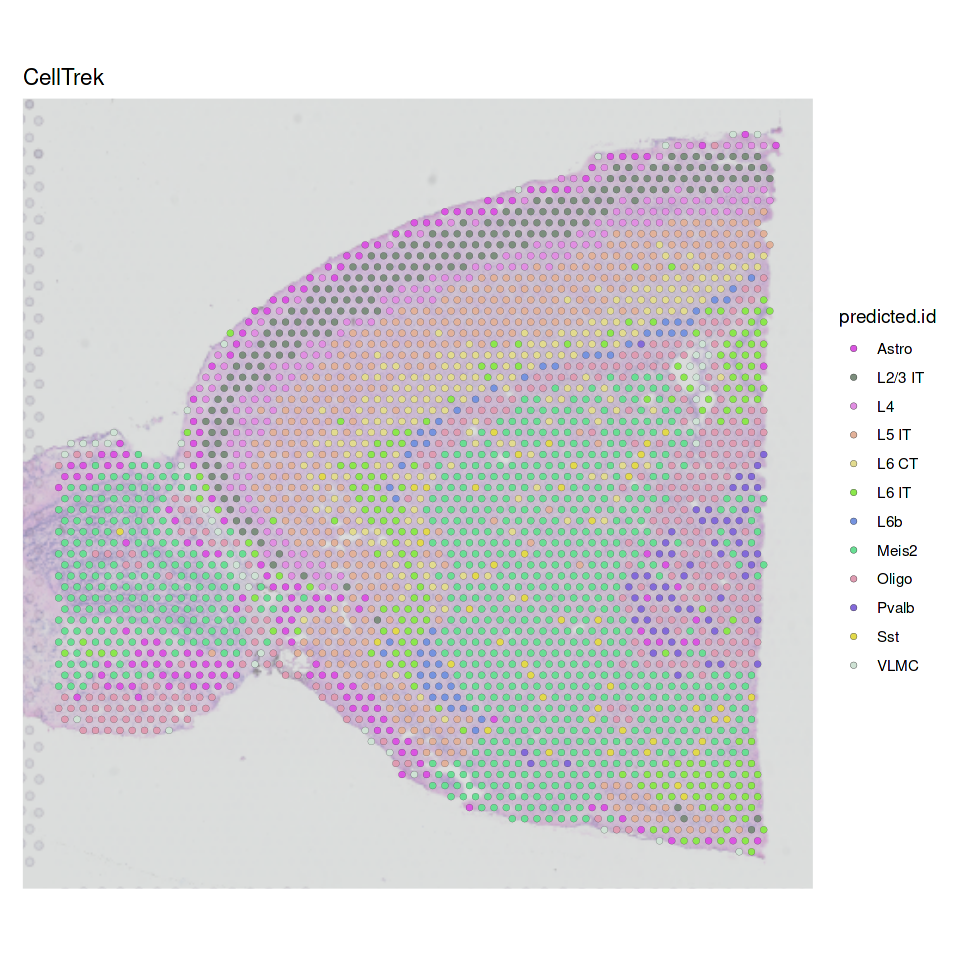

In [51]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(seurat.res, group.by = 'predicted.id', pt.size = 0.8, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('CellTrek')
ggsave(file.path(out.figs.dir, 'seurat.entire.UMAP.pdf'), width = 8, height = 6)

In [52]:
dim(seurat.res)

[1] 15996  2696

In [54]:
f.ctypes <- intersect(names(markers), seurat.res$predicted.id %>% unique)
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(seurat.res, predicted.id == ct) %>% Cells
    obj.sub <- seurat.res[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 0.5, group.by = 'predicted.id', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

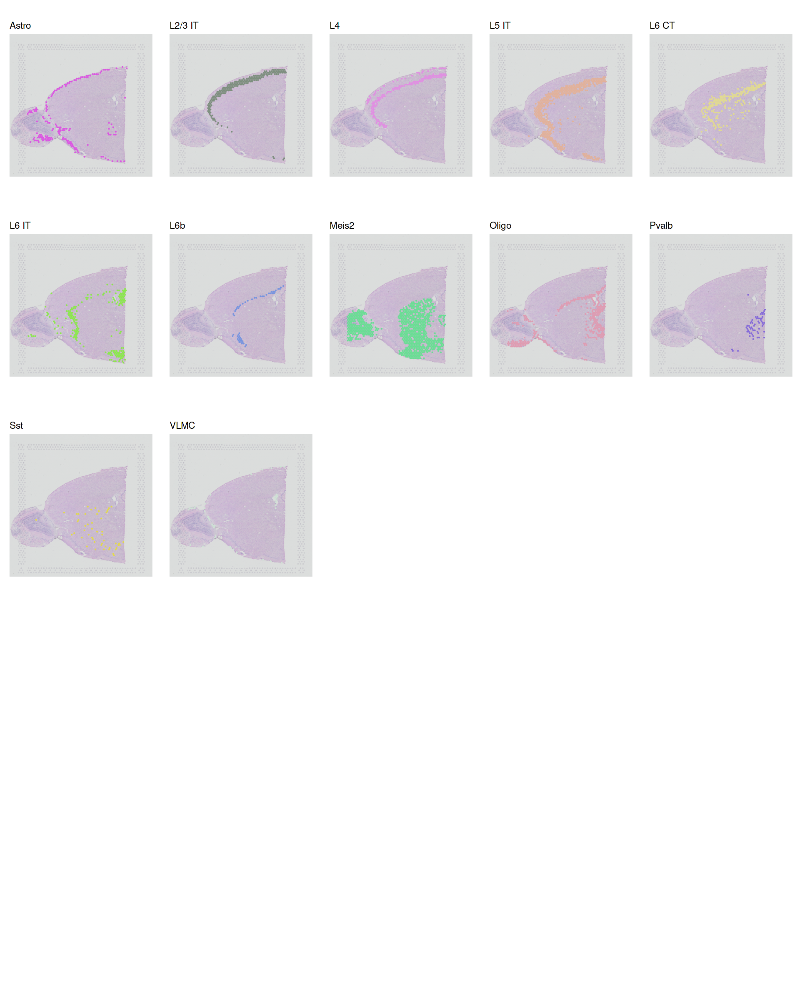

In [55]:
options(repr.plot.width = 16, repr.plot.height = 20)
ggarrange(plotlist = gps, nrow = 5, ncol = 5)
ggsave(file.path(out.figs.dir, 'seurat.split.UMAP.pdf'), width = 16, height = 20)
ggsave(file.path(out.figs.dir, 'seurat.split.UMAP.eps'), width = 16, height = 20)

### HVG comparisons

In [78]:
options(future.globals.maxSize = 20 * 1024^3)  

In [178]:
exprDecom <- function(cell2spatial, cytospace, cell.trek, tangram) {
    sp.lst <- split(cell2spatial$Cell, cell2spatial$SpotName)
    sc.mat <- GetAssayData(cell2spatial, slot = 'count')

    mat <- parallel::mclapply(sp.lst, function(xx) {
        if (length(xx) > 1) rowSums(sc.mat[, xx])
        else sc.mat[, xx]
    }, mc.cores = 5) %>% do.call(cbind, .) %>% as.data.frame

    obj.cell2spatial <- CreateSeuratObject(count = mat) 
    sc.mat <- GetAssayData(cytospace, slot = 'count')
    sp.lst <- split(cytospace$UniqueCID, cytospace$SpotID)
    mat <- parallel::mclapply(sp.lst, function(xx) {
        if (length(xx) > 1) rowSums(sc.mat[, xx])
        else sc.mat[, xx]
    }, mc.cores = 5) %>% do.call(cbind, .) %>% as.data.frame
    obj.cytospace <- CreateSeuratObject(count = mat) 

    sc.mat <- GetAssayData(cell.trek, slot = 'count')
    sp.lst <- split(as.vector(cell.trek$id_raw), as.vector(cell.trek$Spot))
    mat <- parallel::mclapply(sp.lst, function(xx) {
        if (length(xx) > 1) rowSums(sc.mat[, xx])
        else sc.mat[, xx]
    }, mc.cores = 5) %>% do.call(cbind, .) %>% as.data.frame
    obj.celltrek <- CreateSeuratObject(count = mat) 

    sc.mat <- GetAssayData(tangram, slot = 'count')
    sp.lst <- split(tangram$X, tangram$SpotID)
    mat <- parallel::mclapply(sp.lst, function(xx) {
        if (length(xx) > 1) rowSums(sc.mat[, xx])
        else sc.mat[, xx]
    }, mc.cores = 5) %>% do.call(cbind, .) %>% as.data.frame
    obj.tangram <- CreateSeuratObject(count = mat) 
    return(list(Cell2Spatial = obj.cell2spatial, CytoSPACE = obj.cytospace, CellTrek = obj.celltrek, Tangram = obj.tangram))
}

In [179]:
hvgConserve <- function(obj.lst, ref.name = 'brain') {
    ref.obj <- obj.lst[[ref.name]] 
    DefaultAssay(ref.obj) <- 'Spatial'
    ref.obj <- ref.obj %>% NormalizeData %>% FindVariableFeatures(nfeatures = 3000)
    ref.hvgs <- VariableFeatures(ref.obj)
    obj.lst.sub <- obj.lst[setdiff(names(obj.lst), ref.name)]
    hvg.res <- lapply(obj.lst.sub, function(qry.obj) {
        DefaultAssay(qry.obj) <- 'RNA'
        qry.obj <- qry.obj %>% NormalizeData %>% FindVariableFeatures(nfeatures = 3000)
        qry.hvgs <- VariableFeatures(qry.obj)
        length(intersect(ref.hvgs, qry.hvgs)) / min(length(ref.hvgs), length(qry.hvgs))
    }) %>% unlist %>% as.vector
    return(hvg.res)
}

In [180]:
obj.lst <- exprDecom(cell2spatial, cytospace, cell.trek, tangram)

In [181]:
obj.lst[['brain']] <-  brain.st

In [182]:
hvg.res <- hvgConserve(obj.lst) %>% `names<-`(names(obj.lst)[1 : 4])

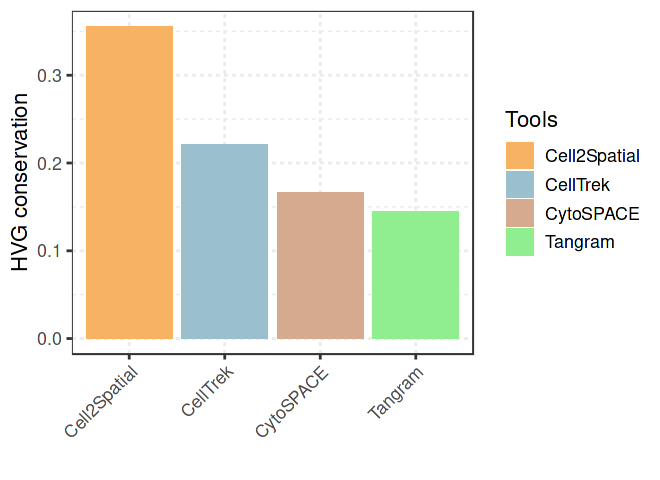

In [183]:
options(repr.plot.width = 5.5, repr.plot.height = 4)
ggplot(data.frame(HVG = hvg.res, Tools = names(hvg.res)), aes(x = Tools, y = HVG, fill = Tools)) + geom_bar(stat = 'identity') + scale_fill_manual(values = MTH_COLOR[names(hvg.res)]) + theme_bw(base_size = 13) + xlab('') + theme(panel.grid = element_line(linetype = 'dashed'), axis.text.x = element_text(hjust = 1, angle = 45)) + ylab('HVG conservation')
ggsave(file.path(out.figs.dir, 'hvg.conserve.brain.pdf'), width = 5, height = 4)

### Comparison of the performace based on cellular compositions, take CARD deconvolution results as standard

In [41]:
card.res <- readRDS('../2.results/stxBrain/data/stxBrain.card.RDS')$decon

In [47]:
prop.card <- card.res@Proportion_CARD * 10
prop.card <- apply(prop.card, 1, ceiling) %>% t

In [48]:
prop <- rep(0, length(markers)) %>% `names<-`(names(markers))
prop.card <- colSums(prop.card) / sum(prop.card) * 100
prop.card <- prop.card[names(prop)]

In [49]:
prop <- rep(0, length(markers)) %>% `names<-`(names(markers))
prop.cell2spatial <- cell2spatial$CellType %>% table %>% {./sum(.)} * 100
prop[names(prop.cell2spatial)] <- prop.cell2spatial
prop.cell2spatial <- prop

prop <- rep(0, length(markers)) %>% `names<-`(names(markers))
prop.cytospace <- cytospace$CellType %>% table %>% {./sum(.)} * 100
prop[names(prop.cytospace)] <- prop.cytospace
prop.cytospace <- prop

prop <- rep(0, length(markers)) %>% `names<-`(names(markers))
prop.cell.trek <- cell.trek$subclass %>% table %>% {./sum(.)} * 100
prop[names(prop.cell.trek)] <- prop.cell.trek
prop.cell.trek <- prop

prop <- rep(0, length(markers)) %>% `names<-`(names(markers))
prop.tangram <- tangram$subclass %>% table %>% {./sum(.)} * 100
prop[names(prop.tangram)] <- prop.tangram
prop.tangram <- prop

prop <- rep(0, length(markers)) %>% `names<-`(names(markers))
prop.seurat <- seurat.res$predicted.id %>% table %>% {./sum(.)} * 100
prop[names(prop.seurat)] <- prop.seurat
prop.seurat <- prop

In [50]:
prop.df <- cbind.data.frame(CARD = prop.card, Cell2Spatial = prop.cell2spatial, CytoSPACE = prop.cytospace, CellTrek = prop.cell.trek, Tangram = prop.tangram, Seurat = prop.seurat)

In [51]:
openxlsx::write.xlsx(prop.df, file = file.path(out.data.dir, 'methods.corr.vs.card.xlsx'))

In [56]:
prop.df$CellType <- rownames(prop.df)
gps <- lapply(colnames(prop.df)[2 : (ncol(prop.df) - 1)], function(meth) {
    plot.df.sub <- prop.df[, c('CARD', meth, 'CellType')] %>% `colnames<-`(c('CARD', 'Y', 'CellType'))
    ggplot(plot.df.sub, aes(x = CARD, y = Y)) + geom_point(size = 4, aes(color = CellType)) + theme_classic() + scale_color_manual(values = cell.colors) + 
        geom_smooth(method = lm, se = TRUE) + ylab(meth) + ggpubr::stat_cor(method = "pearson")
})

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


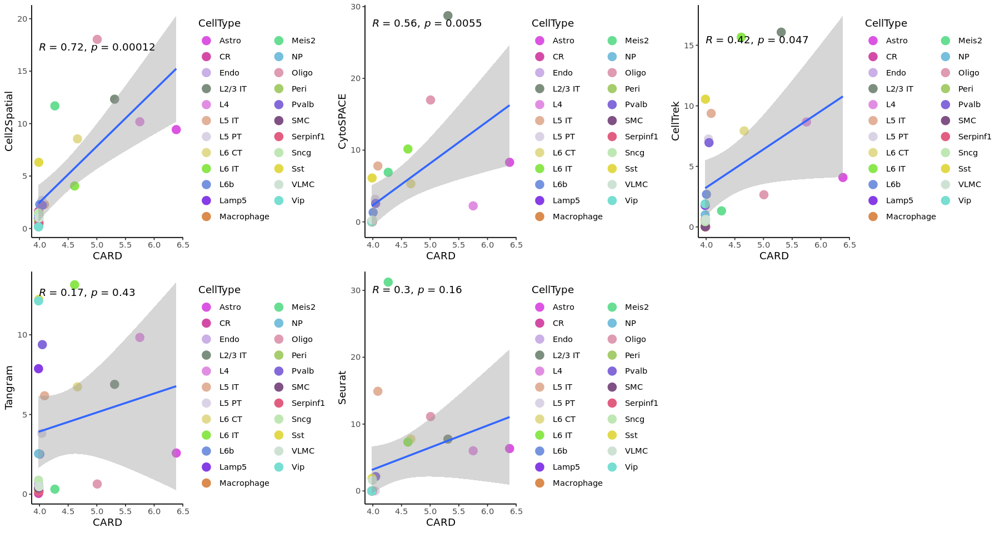

In [57]:
options(repr.plot.width = 15, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 3)
ggsave(file.path(out.figs.dir, 'methods.corr.vs.card.pdf'), width = 15, height = 8)

### Calculate the K-distance for each cell type

##### Cell2Spatial

In [90]:
cortex <- subset(cell2spatial, anterior1_imagerow > 400 | anterior1_imagecol < 150, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 275 & anterior1_imagecol > 370, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 250 & anterior1_imagecol > 440, invert = TRUE)

In [91]:
ref.obj <- subset(cortex, CellType == 'Astro')
ref.coord <- GetTissueCoordinates(ref.obj)[colnames(ref.obj), ]

k <- 10
obj.cells <- c('L2/3 IT', 'L4', 'L5 IT', 'L5 PT', 'NP', 'L6 IT', 'L6 CT', 'L6b', 'Oligo')
dim(ref.coord)

[1] 742   2

In [92]:
dist.res <- lapply(obj.cells, function(ct) {
    qry.obj <- subset(cortex, CellType == ct)
    qry.coord <- GetTissueCoordinates(qry.obj)[colnames(qry.obj), ]
    dis.vec <- apply(qry.coord, 1, function(xx) {
        dis.res <- apply(ref.coord, 1, function(yy) {
            distances <- sqrt((xx[1] - yy[1])^2 + (xx[2] - yy[2])^2)         
        }) %>% sort 
        dis.res[k]
    })
    res.df <- cbind.data.frame(Dist = dis.vec, CellType = ct)
}) %>% do.call(rbind, .)

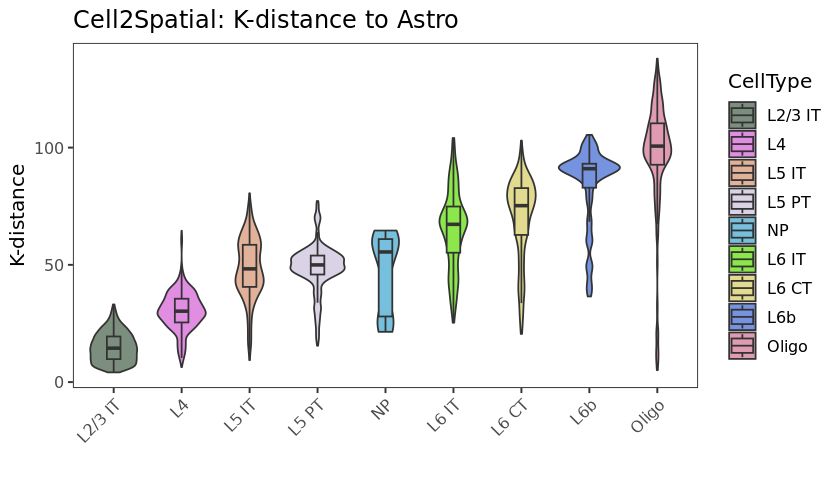

In [93]:
options(repr.plot.width = 7, repr.plot.height = 4)

order <- aggregate(Dist ~ CellType, dist.res, 'median') %>% { .[order(.[, 2]), ]}
dist.res$CellType <- factor(dist.res$CellType, levels = order[, 1])
ggplot(dist.res, aes(x = CellType, y = Dist, fill = CellType)) + geom_violin() + geom_boxplot(outlier.shape = NA, width = 0.2) + theme_bw(base_size = 12) + scale_fill_manual(values = cell.colors[obj.cells]) + theme(panel.grid = element_blank(), axis.text.x = element_text(angle = 45, hjust = 1)) + xlab('') + ylab('K-distance') + ggtitle('Cell2Spatial: K-distance to Astro')

openxlsx::write.xlsx(dist.res, file = file.path(out.data.dir, 'cell2spatial.distance.xlsx'))
ggsave(file.path(out.figs.dir, 'cell2spatial.distance.pdf'), width = 6, height = 4)

##### CytoSPACE

In [102]:
cortex <- subset(cytospace, anterior1_imagerow > 400 | anterior1_imagecol < 150, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 275 & anterior1_imagecol > 370, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 250 & anterior1_imagecol > 440, invert = TRUE)

In [103]:
ref.obj <- subset(cortex, CellType == 'Astro')
ref.coord <- GetTissueCoordinates(ref.obj)[colnames(ref.obj), ]

k <- 10
obj.cells <- c('L2/3 IT', 'L4', 'L5 IT', 'L5 PT', 'NP', 'L6 IT', 'L6 CT', 'L6b', 'Oligo')
dim(ref.coord)

[1] 55  2

In [106]:
dist.res <- lapply(intersect(obj.cells, unique(cortex$CellType)), function(ct) {
    qry.obj <- subset(cortex, CellType == ct)
    qry.coord <- GetTissueCoordinates(qry.obj)[colnames(qry.obj), ]
    dis.vec <- apply(qry.coord, 1, function(xx) {
        dis.res <- apply(ref.coord, 1, function(yy) {
            distances <- sqrt((xx[1] - yy[1])^2 + (xx[2] - yy[2])^2)         
        }) %>% sort 
        dis.res[k]
    })
    res.df <- cbind.data.frame(Dist = dis.vec, CellType = ct)
}) %>% do.call(rbind, .)

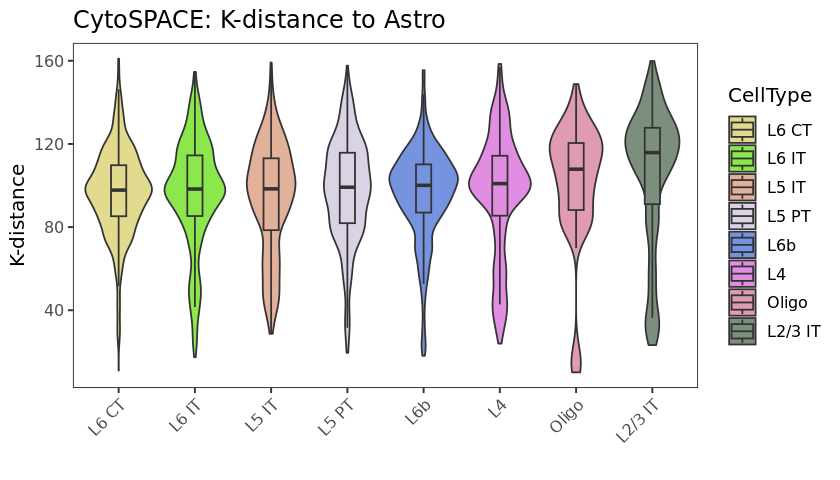

In [109]:
options(repr.plot.width = 7, repr.plot.height = 4)

order <- aggregate(Dist ~ CellType, dist.res, 'median') %>% { .[order(.[, 2]), ]}
dist.res$CellType <- factor(dist.res$CellType, levels = order[, 1])
ggplot(dist.res, aes(x = CellType, y = Dist, fill = CellType)) + geom_violin() + geom_boxplot(outlier.shape = NA, width = 0.2) + theme_bw(base_size = 12) + scale_fill_manual(values = cell.colors[obj.cells]) + theme(panel.grid = element_blank(), axis.text.x = element_text(angle = 45, hjust = 1)) + xlab('') + ylab('K-distance') + ggtitle('CytoSPACE: K-distance to Astro')

openxlsx::write.xlsx(dist.res, file = file.path(out.data.dir, 'cytospace.distance.xlsx'))
ggsave(file.path(out.figs.dir, 'cytospace.distance.pdf'), width = 6, height = 4)

##### CellTrek

In [122]:
cortex <- subset(cell.trek, anterior1_imagerow > 400 | anterior1_imagecol < 150, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 275 & anterior1_imagecol > 370, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 250 & anterior1_imagecol > 440, invert = TRUE)

In [126]:
ref.obj <- subset(cortex, subclass == 'Astro')
ref.coord <- GetTissueCoordinates(ref.obj)[colnames(ref.obj), ]

k <- 10
obj.cells <- c('L2/3 IT', 'L4', 'L5 IT', 'L5 PT', 'NP', 'L6 IT', 'L6 CT', 'L6b', 'Oligo')
dim(ref.coord)

[1] 193   2

In [128]:
dist.res <- lapply(intersect(obj.cells, unique(cortex$subclass)), function(ct) {
    qry.obj <- subset(cortex, subclass == ct)
    qry.coord <- GetTissueCoordinates(qry.obj)[colnames(qry.obj), ]
    dis.vec <- apply(qry.coord, 1, function(xx) {
        dis.res <- apply(ref.coord, 1, function(yy) {
            distances <- sqrt((xx[1] - yy[1])^2 + (xx[2] - yy[2])^2)         
        }) %>% sort 
        dis.res[k]
    })
    res.df <- cbind.data.frame(Dist = dis.vec, CellType = ct)
}) %>% do.call(rbind, .)

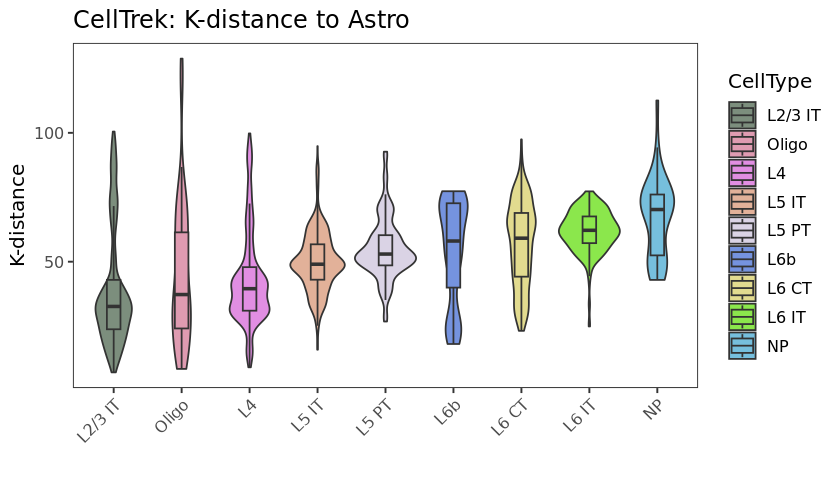

In [130]:
options(repr.plot.width = 7, repr.plot.height = 4)

order <- aggregate(Dist ~ CellType, dist.res, 'median') %>% { .[order(.[, 2]), ]}
dist.res$CellType <- factor(dist.res$CellType, levels = order[, 1])
ggplot(dist.res, aes(x = CellType, y = Dist, fill = CellType)) + geom_violin() + geom_boxplot(outlier.shape = NA, width = 0.2) + theme_bw(base_size = 12) + scale_fill_manual(values = cell.colors[obj.cells]) + theme(panel.grid = element_blank(), axis.text.x = element_text(angle = 45, hjust = 1)) + xlab('') + ylab('K-distance') + ggtitle('CellTrek: K-distance to Astro')

openxlsx::write.xlsx(dist.res, file = file.path(out.data.dir, 'celltrek.distance.xlsx'))
ggsave(file.path(out.figs.dir, 'celltrek.distance.pdf'), width = 6, height = 4)

##### Tangram

In [131]:
cortex <- subset(tangram, anterior1_imagerow > 400 | anterior1_imagecol < 150, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 275 & anterior1_imagecol > 370, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 250 & anterior1_imagecol > 440, invert = TRUE)

In [132]:
ref.obj <- subset(cortex, subclass == 'Astro')
ref.coord <- GetTissueCoordinates(ref.obj)[colnames(ref.obj), ]

k <- 10
obj.cells <- c('L2/3 IT', 'L4', 'L5 IT', 'L5 PT', 'NP', 'L6 IT', 'L6 CT', 'L6b', 'Oligo')
dim(ref.coord)

[1] 59  2

In [133]:
dist.res <- lapply(intersect(obj.cells, unique(cortex$subclass)), function(ct) {
    qry.obj <- subset(cortex, subclass == ct)
    qry.coord <- GetTissueCoordinates(qry.obj)[colnames(qry.obj), ]
    dis.vec <- apply(qry.coord, 1, function(xx) {
        dis.res <- apply(ref.coord, 1, function(yy) {
            distances <- sqrt((xx[1] - yy[1])^2 + (xx[2] - yy[2])^2)         
        }) %>% sort 
        dis.res[k]
    })
    res.df <- cbind.data.frame(Dist = dis.vec, CellType = ct)
}) %>% do.call(rbind, .)

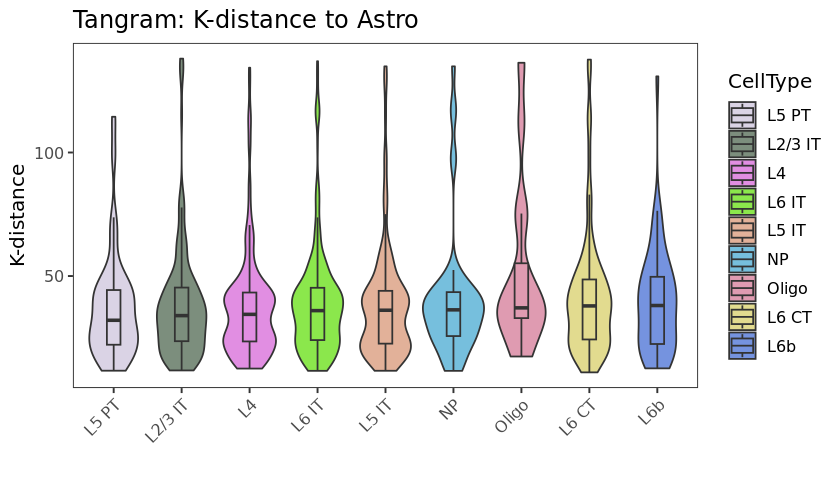

In [134]:
options(repr.plot.width = 7, repr.plot.height = 4)

order <- aggregate(Dist ~ CellType, dist.res, 'median') %>% { .[order(.[, 2]), ]}
dist.res$CellType <- factor(dist.res$CellType, levels = order[, 1])
ggplot(dist.res, aes(x = CellType, y = Dist, fill = CellType)) + geom_violin() + geom_boxplot(outlier.shape = NA, width = 0.2) + theme_bw(base_size = 12) + scale_fill_manual(values = cell.colors[obj.cells]) + theme(panel.grid = element_blank(), axis.text.x = element_text(angle = 45, hjust = 1)) + xlab('') + ylab('K-distance') + ggtitle('Tangram: K-distance to Astro')

openxlsx::write.xlsx(dist.res, file = file.path(out.data.dir, 'tangram.distance.xlsx'))
ggsave(file.path(out.figs.dir, 'tangram.distance.pdf'), width = 6, height = 4)

##### Seurat 

In [56]:
cortex <- subset(seurat.res, anterior1_imagerow > 400 | anterior1_imagecol < 150, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 275 & anterior1_imagecol > 370, invert = TRUE)
cortex <- subset(cortex, anterior1_imagerow > 250 & anterior1_imagecol > 440, invert = TRUE)

In [58]:
ref.obj <- subset(cortex, predicted.id == 'Astro')
ref.coord <- GetTissueCoordinates(ref.obj)[colnames(ref.obj), ]

k <- 10
obj.cells <- c('L2/3 IT', 'L4', 'L5 IT', 'L5 PT', 'NP', 'L6 IT', 'L6 CT', 'L6b', 'Oligo')
dim(ref.coord)

[1] 68  2

In [59]:
dist.res <- lapply(intersect(obj.cells, unique(cortex$predicted.id)), function(ct) {
    qry.obj <- subset(cortex, predicted.id == ct)
    qry.coord <- GetTissueCoordinates(qry.obj)[colnames(qry.obj), ]
    dis.vec <- apply(qry.coord, 1, function(xx) {
        dis.res <- apply(ref.coord, 1, function(yy) {
            distances <- sqrt((xx[1] - yy[1])^2 + (xx[2] - yy[2])^2)         
        }) %>% sort 
        dis.res[k]
    })
    res.df <- cbind.data.frame(Dist = dis.vec, CellType = ct)
}) %>% do.call(rbind, .)

In [61]:
options(repr.plot.width = 7, repr.plot.height = 4)

order <- aggregate(Dist ~ CellType, dist.res, 'median') %>% { .[order(.[, 2]), ]}
dist.res$CellType <- factor(dist.res$CellType, levels = order[, 1])
gp <- ggplot(dist.res, aes(x = CellType, y = Dist, fill = CellType)) + geom_violin() + geom_boxplot(outlier.shape = NA, width = 0.2) + theme_bw(base_size = 12) + scale_fill_manual(values = cell.colors[obj.cells]) + theme(panel.grid = element_blank(), axis.text.x = element_text(angle = 45, hjust = 1)) + xlab('') + ylab('K-distance') + ggtitle('Tangram: K-distance to Astro')

openxlsx::write.xlsx(dist.res, file = file.path(out.data.dir, 'seurat.distance.xlsx'))
ggsave(file.path(out.figs.dir, 'seurat.distance.pdf'), width = 6, height = 4)

In [100]:
cell2spatial.dist <- openxlsx::read.xlsx(file.path(out.data.dir, 'cell2spatial.distance.xlsx')) %>% cbind.data.frame(., Method = 'Cell2Spatial')
cytospace.dist <- openxlsx::read.xlsx(file.path(out.data.dir, 'cytospace.distance.xlsx')) %>% cbind.data.frame(., Method = 'CytoSPACE')
celltrek.dist <- openxlsx::read.xlsx(file.path(out.data.dir, 'celltrek.distance.xlsx')) %>% cbind.data.frame(., Method = 'CellTrek')
tangram.dist <- openxlsx::read.xlsx(file.path(out.data.dir, 'tangram.distance.xlsx')) %>% cbind.data.frame(., Method = 'Tangram')
seurat.dist <- openxlsx::read.xlsx(file.path(out.data.dir, 'seurat.distance.xlsx')) %>% cbind.data.frame(., Method = 'Seurat')

plot.df <- rbind.data.frame(cell2spatial.dist, cytospace.dist, celltrek.dist, tangram.dist, seurat.dist)

In [101]:
head(plot.df)

,Dist,CellType,Method
,<dbl>,<chr>,<chr>
1,15.06558,L2/3 IT,Cell2Spatial
2,13.27751,L2/3 IT,Cell2Spatial
3,14.37915,L2/3 IT,Cell2Spatial
4,11.74131,L2/3 IT,Cell2Spatial
5,13.89164,L2/3 IT,Cell2Spatial
6,15.60477,L2/3 IT,Cell2Spatial


In [103]:
order <- aggregate(Dist ~ CellType, cell2spatial.dist, 'median') %>% { .[order(.[, 2]), ]}
orde

,CellType,Dist
,<chr>,<dbl>
1,L2/3 IT,14.46203
2,L4,30.24108
3,L5 IT,48.29358
4,L5 PT,49.96990
8,NP,55.49782
6,L6 IT,67.27939
5,L6 CT,75.23846
7,L6b,90.99901
9,Oligo,100.64305


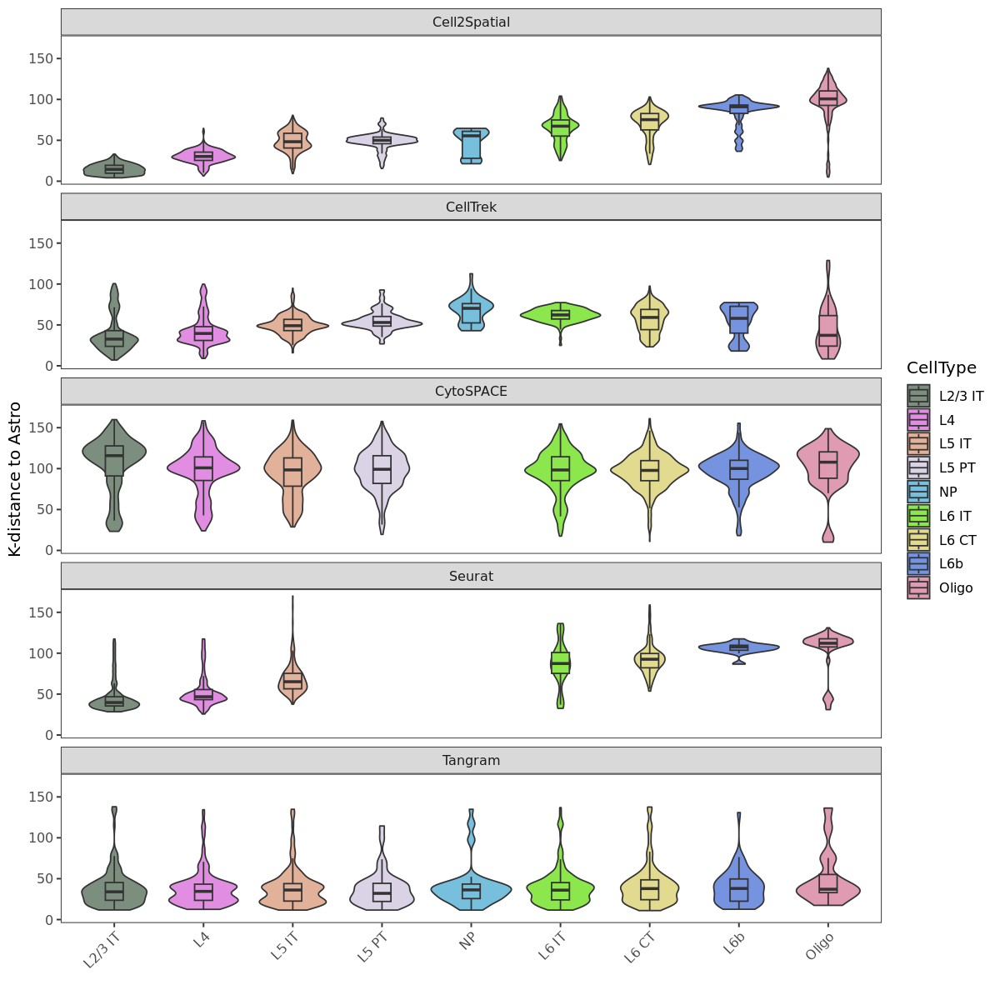

In [117]:
options(repr.plot.width = 10, repr.plot.height = 10)
plot.df$CellType <- factor(plot.df$CellType, levels = order[, 1])
ggplot(plot.df, aes(x = CellType, y = Dist, fill = CellType)) + geom_violin() + geom_boxplot(outlier.shape = NA, width = 0.2) + theme_bw(base_size = 12) + theme(panel.grid = element_blank(), axis.text.x = element_text(angle = 45, hjust = 1)) + xlab('') + ylab('K-distance to Astro') + facet_wrap(~Method, nrow = 5) + scale_fill_manual(values = cell.colors[obj.cells])
ggsave(file.path(out.figs.dir, 'merged.methods.distance.pdf'), width = 10, height = 10)

In [106]:
names(MTH_COLOR)

[1] "Reference"    "Cell2Spatial" "CytoSPACE"    "CellTrek"     "Tangram"     
[6] "Seurat"

### Number of cell types projected

In [149]:
number.cts <- c(
    Reference = length(markers),
    Cell2Spatial = unique(cell2spatial$CellType) %>% length, 
    CytoSPACE = unique(cytospace$CellType) %>% length, 
    CellTrek = unique(cell.trek$subclass) %>% length, 
    Tangram = unique(tangram$subclass) %>% length, 
    Seurat = unique(seurat.res$predicted.id) %>% length    
)
number.cts

Reference Cell2Spatial    CytoSPACE     CellTrek      Tangram       Seurat 
          23           23           17           23           23           12

png 
  2

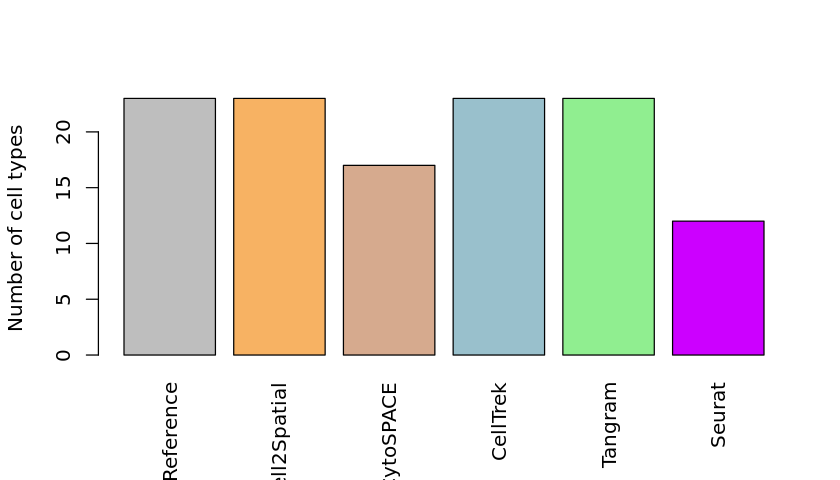

In [151]:
pdf(file.path(out.figs.dir, 'number.of.ctypes.pdf'), width = 6, height = 4)
bp <- barplot(number.cts, las = 3, ylab = 'Number of cell types', col = MTH_COLOR)
text(bp, 20, labels = round(number.cts, digits = 2))

dev.off()
barplot(number.cts, las = 3, ylab = 'Number of cell types', col = MTH_COLOR)

### Simulation the pseudo-spatial data

In [8]:
brain.sc <- readRDS(file = file.path(out.data.dir, 'brain.sc.RDS'))
brain.st <- readRDS(file = file.path(out.data.dir, 'brain.st.RDS'))

In [8]:
simSpots <- function(obj.sp, obj.sc.train, markers, lambda = 10) {
    ovp.genes <- intersect(unlist(markers), rownames(obj.sp))
    #ovp.genes <- intersect(FindVariableFeatures(obj.sp) %>% VariableFeatures, FindVariableFeatures(obj.sc.train) %>% VariableFeatures)
    sp.ref <- obj.sp[ovp.genes, ] %>% GetAssayData(., slot = 'data', assay = 'SCT') %>% as.matrix
    sc.prop <- obj.sc.train[ovp.genes, ] %>% GetAssayData(., slot = 'data', assay = 'SCT') %>% as.matrix
    cor.mat <- cor(sp.ref, sc.prop)
    rand.cnt <- rpois(n = ncol(cor.mat), lambda = lambda) %>% `names<-`(rownames(cor.mat)) %>% { . + 2}
    sp.sim <- lapply(rownames(cor.mat), function(sp) {
        cor.vec <- cor.mat[sp, ]
        colnames(cor.mat)[order(cor.vec) %>% rev][1 : rand.cnt[sp]]
    }) %>% `names<-`(rownames(cor.mat))
    return(sp.sim)
}

In [9]:
markers <- readRDS('../0.data/sctBrain.markers.RDS')
brain.sc$cellType <- Idents(brain.sc) %>% as.vector
obj.sc.train <- downSamplSeurat(brain.sc, cnt = 1000)
obj.st.sub <- brain.st

In [10]:
options(future.globals.maxSize = 5000000 * 1024^2, future.seed = TRUE)

In [11]:
lambda <- 5; sn <- 'stxBrain'
sim.res <- simSpots(brain.st, obj.sc.train, markers, lambda = lambda)
ref.ctpes <- Idents(obj.sc.train)
sim.coord <- reformatSimCoord(sim.res, brain.st)
sim.coord$CellType <- ref.ctpes[sim.coord$CellName]
saveRDS(sim.coord, file = file.path(out.data.dir, sprintf('%s.true.coord.rds', sn)))

In [21]:
lapply(sim.res, function(xx) length(xx)) %>% unlist %>% max
lapply(sim.res, function(xx) length(xx)) %>% unlist %>% sum       

[1] 17

[1] 18785

In [20]:
for (nois.level in c(0, 5, 10, 15, 20)) {
    print(sprintf('Noise lelve: %g', nois.level))
    sc.expr <- GetAssayData(obj.sc.train, slot = 'count') %>% as.data.frame
    if (nois.level > 0) {
        idxes <- sample(nrow(sc.expr), floor(nrow(sc.expr) * nois.level * 0.01))
        rand.shuffle <- sc.expr[idxes, ]
        rand.shuffle <- rand.shuffle[, sample(ncol(rand.shuffle))]
        colnames(rand.shuffle) <- colnames(sc.expr)
        sc.expr[idxes, ] <- rand.shuffle
    }       
    sim.expr <- parallel::mclapply(sim.res, function(sim.vec) {
        sc.expr[, sim.vec] %>% rowSums(.)
    }, mc.cores = 10) %>% do.call(cbind, .) %>% as.data.frame   
    colnames(sim.expr) <- gsub('-', '\\.',  colnames(sim.expr))
    obj.sim <- CreateSeuratObject(counts = sim.expr, project = 'Sim', assay = 'Spatial') %>% SCTransform(verbose = FALSE, assay = "Spatial")
    obj.sim@images <- brain.st@images
    obj.sim@meta.data <- brain.st@meta.data
    rownames(obj.sim@meta.data) <- gsub('-', '\\.', rownames(brain.st@meta.data))
    rownames(obj.sim@images[[1]]@coordinates) <- gsub('-', '.', rownames(obj.sim@images[[1]]@coordinates))
    saveRDS(obj.sim, file = file.path(out.data.dir, sprintf('%s.sim.%g.rds', sn, nois.level)))
}

[1] "Noise lelve: 0"
[1] "Noise lelve: 5"
[1] "Noise lelve: 10"
[1] "Noise lelve: 15"
[1] "Noise lelve: 20"


In [168]:
obj.sc.test <- downSamplSeurat(brain.sc, cnt = 1000)

In [169]:
object.version <- attr(obj.sc.test, "version")
print(object.version)

[1] ‘3.1.1.9023’


In [170]:
obj.sc.test <- UpdateSeuratObject(obj.sc.test)

Validating object structure

Updating object slots

Ensuring keys are in the proper structure

Ensuring feature names don't have underscores or pipes

Object representation is consistent with the most current Seurat version



In [171]:
SeuratDisk::SaveH5Seurat(obj.sc.test, filename = "obj.sc.test.h5Seurat", verbose = FALSE)
SeuratDisk::Convert("obj.sc.test.h5Seurat", dest = "h5ad", verbose = FALSE)

Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Creating h5Seurat file for version 3.1.5.9900

Validating h5Seurat file



In [172]:
file.rename('obj.sc.test.h5Seurat', './.tmp/obj.sc.test.h5Seurat')
file.rename('obj.sc.test.h5ad', './.tmp/obj.sc.test.h5ad')

[1] TRUE

[1] TRUE

### Analysis the Simulation results

In [118]:
out.figs.dir <- '../2.results/sim/figs'
out.data.dir <- '../2.results/sim/data'

In [28]:
obj.list <- lapply(c(0, 5, 10, 15, 20), function(idx) {
    obj.st.sim <- readRDS(sprintf('../2.results/stxBrain/data/stxBrain.sim.%g.rds', idx))
    obj.st.sim <- SCTransform(obj.st.sim, assay = "Spatial", verbose = FALSE) %>%
        RunPCA(., assay = "SCT", verbose = FALSE) %>%
        FindNeighbors(., reduction = "pca", dims = 1:30, verbose = FALSE) %>%
        FindClusters(., verbose = FALSE, res = 0.3) %>%
        RunUMAP(., reduction = "pca", dims = 1:30, verbose = FALSE)
})

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'Bioc

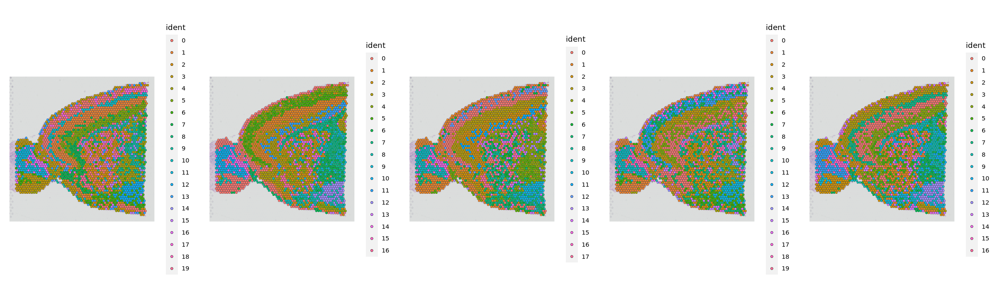

In [29]:
options(repr.plot.width = 20, repr.plot.height = 6)
gps <- lapply(obj.list, function(xx) {
    SpatialDimPlot(xx, image.alpha = 0.5)
})
ggarrange(plotlist = gps, ncol = 5)
ggsave(file.path(out.figs.dir, 'sim.noise.levels.UMAP.pdf'), width = 20, height = 6)

In [30]:
gps <- lapply(c(0, 5, 10, 15, 20), function(nois.level) {
    print(sprintf('Noise lelve: %g', nois.level))
    sc.expr <- GetAssayData(obj.sc.train, slot = 'count')
    sim.expr <- lapply(sim.res, function(sim.vec) {
        sc.expr[, sim.vec]
    }) %>% do.call(cbind, .) %>% as.data.frame
    if (nois.level > 0) {
        idxes <- sample(nrow(sim.expr), floor(nrow(sim.expr) * nois.level * 0.01))
        rand.shuffle <- sim.expr[idxes, ]
        rand.shuffle <- rand.shuffle[, sample(ncol(rand.shuffle))]
        sim.expr[idxes, ] <- rand.shuffle
    }
    raw.cells <- colnames(sim.expr)
    colnames(sim.expr) <- make.unique(raw.cells)       
    obj.sim <- CreateSeuratObject(counts = sim.expr, project = 'Sim', assay = 'RNA') %>% 
        SCTransform(verbose = FALSE, assay = "RNA")  %>% 
        RunPCA(., assay = "SCT", verbose = FALSE) %>%
        FindNeighbors(., reduction = "pca", dims = 1:30, verbose = FALSE) %>%
        FindClusters(., verbose = FALSE, res = 0.3) %>%
        RunUMAP(., reduction = "pca", dims = 1:30, verbose = FALSE)
    
    obj.sim$CellType <- obj.sc.train$cellType[raw.cells]
    obj.sim
})

[1] "Noise lelve: 0"


Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’



[1] "Noise lelve: 5"


Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’



[1] "Noise lelve: 10"


Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’



[1] "Noise lelve: 15"


Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’



[1] "Noise lelve: 20"


Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

